<a href="https://colab.research.google.com/github/madinatulzahra/pm-turi4-clustering/blob/main/pm_turi4_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

C. LANGKAH PRAKTIKUM

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Membuat dataset buatan (usia, pendapatan, skor_belanja)
np.random.seed(42)
df = pd.DataFrame({
    'usia': np.random.randint(18, 60, 100),
    'pendapatan': np.random.randint(15, 100, 100),
    'skor_belanja': np.random.randint(1, 100, 100)
})

# Scaling fitur wajib sebelum K-Means
X_scaled = StandardScaler().fit_transform(df)

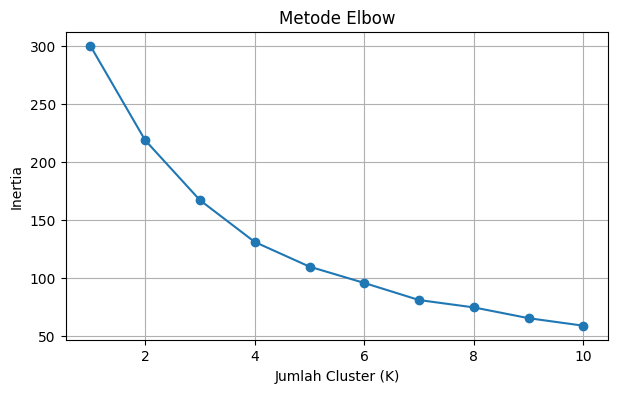

In [13]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.title('Metode Elbow')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [14]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
0    40
1    33
2    27
Name: count, dtype: int64


In [15]:
print("Silhouette Score K=3:", silhouette_score(X_scaled, df['cluster']))

Silhouette Score K=3: 0.2654288114709762


In [16]:
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
print(profil)

# Penamaan cluster berdasarkan profil rata-rata:
# Cluster 0: Usia Paruh Baya, Pendapatan Rendah, Skor Belanja Tinggi -> "Anak Muda/Paruh Baya Konsumtif"
# Cluster 1: Usia Muda, Pendapatan Tinggi, Skor Belanja Sedang -> "Eksekutif Muda Hemat"
# Cluster 2: Usia Dewasa, Pendapatan Tinggi, Skor Belanja Rendah -> "Pekerja Senior Hemat"

         usia  pendapatan  skor_belanja
cluster                                
0        42.2        54.9          77.4
1        34.2        76.8          26.3
2        36.0        30.0          29.1


D. LATIHAN MANDIRI

In [17]:
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_k5 = kmeans_5.fit_predict(X_scaled)

print("Silhouette Score (K=3):", round(silhouette_score(X_scaled, df['cluster']), 4))
print("Silhouette Score (K=5):", round(silhouette_score(X_scaled, cluster_k5), 4))

Silhouette Score (K=3): 0.2654
Silhouette Score (K=5): 0.2856


In [18]:
fitur_asli = df[['usia', 'pendapatan', 'skor_belanja']]
kmeans_no_scale = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_no_scale = kmeans_no_scale.fit_predict(fitur_asli)

print("Silhouette Score (Tanpa Scaling):", round(silhouette_score(fitur_asli, cluster_no_scale), 4))

Silhouette Score (Tanpa Scaling): 0.3616


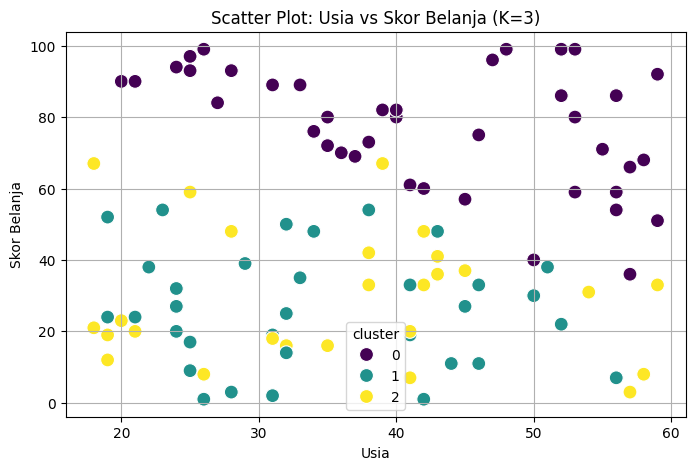

In [19]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='usia', y='skor_belanja', hue='cluster', palette='viridis', s=100)
plt.title('Scatter Plot: Usia vs Skor Belanja (K=3)')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.grid(True)
plt.show()

E. REFLEKSI

1. Bagaimana K-Means menemukan kelompok tanpa label?

Algoritma K-Means menemukan kelompok pada data tanpa label melalui pendekatan unsupervised learning berbasis perhitungan jarak (seperti Euclidean distance). Proses ini diawali dengan menentukan sejumlah $K$ titik pusat (centroid) secara acak. Selanjutnya, setiap titik data dialokasikan ke centroid terdekat. Posisi centroid kemudian diperbarui berdasarkan nilai rata-rata (mean) dari seluruh anggota klaster tersebut. Proses alokasi dan pembaruan ini diulang secara berurutan hingga kondisi konvergen tercapai (posisi centroid tidak lagi berubah secara signifikan).   

2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Metode Elbow menampilkan titik 'siku' pada $K=3$ karena nilai inertia (tingkat variasi data di dalam klaster) mengalami penurunan secara signifikan hingga titik $K=3$. Setelah melewati titik $K=3$, penambahan jumlah klaster (seperti $K=4$ atau $K=5$) hanya memberikan penurunan nilai inertia yang melandai dan tidak lagi signifikan. Oleh karena itu, $K=3$ merupakan jumlah klaster paling optimal yang menyeimbangkan kompleksitas model dan kualitas pengelompokan data.   

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Scaling sangat penting karena K-Means sepenuhnya bergantung pada perhitungan jarak spasial antar titik data. Jika scaling dilewatkan, variabel dengan rentang nilai yang sangat besar (seperti pendapatan) akan mendominasi perhitungan jarak Euclidean. Hal tersebut menyebabkan variabel dengan skala angka kecil (seperti usia) terabaikan, sehingga pengelompokan yang dihasilkan menjadi tidak proporsional dan bias.  